torch.Size([128, 1, 28, 28])
torch.Size([128])
torch.Size([1, 28, 28])
tensor(1)


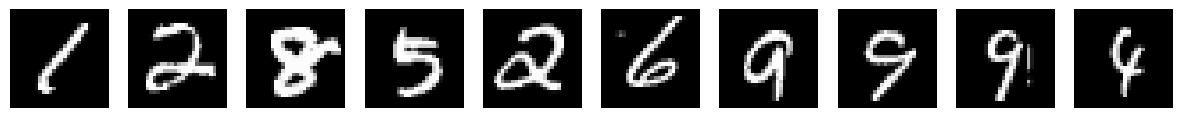

In [505]:
import torch
from torch import nn, optim
from torch.nn import functional as F
from torchvision import datasets, transforms
import torchvision.utils as vutils
from torch.utils.data import DataLoader
from torchsummary import summary
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# fixing random generator for reproducibility
rng = np.random.default_rng(42)
torch.manual_seed(42)

# Data Preparation
# MNIST images are 28x28. We flatten them to 784 vectors.
transform = transforms.Compose([
    transforms.ToTensor(),
])
train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
train_loader = DataLoader(dataset=train_dataset, batch_size=128, shuffle=True)

test_dataset = datasets.MNIST(root='./data', train=False, transform=transform, download=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=True)

images, labels = next(iter(train_loader))
print(images.shape)
print(labels.shape)
print(images[0].shape)
print(labels[0])

plt.figure(figsize=(15, 2))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(images[i].squeeze(), cmap='gray')
    plt.axis('off')
plt.show()

## Task 1 [25% marks] Baseline VAE and training.

In [506]:
class VAE(nn.Module):
    def __init__(self):
        super(VAE, self).__init__()

        # Encoder: 2 Fully Connected Layers
        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 256)

        # Latent space (Mean and Log-Variance)
        self.fc_mu = nn.Linear(256, 20)
        self.fc_logvar = nn.Linear(256, 20)

        # Decoder: 2 Fully Connected Layers
        self.fc3 = nn.Linear(20, 256)
        self.fc4 = nn.Linear(256, 512)

        # Output Layer (Reconstruction)
        self.fc5 = nn.Linear(512, 784)

    def encode(self, x):
        # x: (B, 784)
        h = F.relu(self.fc1(x)) # (B, 512)
        h = F.relu(self.fc2(h)) # (B, 256)
        return self.fc_mu(h), self.fc_logvar(h) # (B, 20)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        # z: (B, 20)
        h = F.relu(self.fc3(z)) # (B, 256)
        h = F.relu(self.fc4(h)) # (B, 512)
        return torch.sigmoid(self.fc5(h)) # (B, 784)

    def forward(self, x):
        mu, logvar = self.encode(x.view(-1, 784))
        z = self.reparameterize(mu, logvar) # (B, 20)
        recon_x = self.decode(z) # (B, 784)
        return recon_x, mu, logvar

In [507]:
# Reconstruction + KL divergence losses summed over all elements and batch
def loss_function(recon_x, x, mu, logvar):
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 784), reduction='sum')

    # KL Divergence term: Analytical solution for Gaussians
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return BCE + KLD, BCE, KLD

In [508]:
def train_vae(model, epochs=20):
    print(f"Training on: {device}")
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    train_losses = []
    recon_losses = []
    kld_losses = []
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        recon_loss = 0
        kl_loss = 0
        for data, _ in train_loader:
            data = data.to(device)
            optimizer.zero_grad()
            recon_batch, mu, logvar = model(data)
            loss, bce, kld = loss_function(recon_batch, data, mu, logvar)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            recon_loss += bce.item()
            kl_loss += kld.item()

        # Calculate averages for the epoch
        num_samples = len(train_loader.dataset)
        avg_loss = train_loss / num_samples
        avg_recon = recon_loss / num_samples
        avg_kld = kl_loss / num_samples
        train_losses.append(avg_loss)
        recon_losses.append(avg_recon)
        kld_losses.append(avg_kld)

        print(f'Epoch: {epoch+1} | Loss: {avg_loss:.4f} | Recon: {avg_recon:.4f} | KLD: {avg_kld:.4f}')

    # Plotting
    fig = plt.figure(figsize=(10, 3))

    # Plot 1: Total Loss
    plt.subplot(1, 3, 1)
    plt.plot(train_losses)
    plt.title("Total Training Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")

    # Plot 2: Reconstruction Loss
    plt.subplot(1, 3, 2)
    plt.plot(recon_losses)
    plt.title("Reconstruction Term (BCE)")
    plt.xlabel("Epochs")

    # Plot 3: KL Divergence
    plt.subplot(1, 3, 3)
    plt.plot(kld_losses)
    plt.title("KL Divergence Term")
    plt.xlabel("Epochs")

    plt.tight_layout()
    plt.show()

    return model


Training on: cpu
Epoch: 1 | Loss: 176.8162 | Recon: 169.3484 | KLD: 7.4678
Epoch: 2 | Loss: 129.4264 | Recon: 115.7606 | KLD: 13.6659
Epoch: 3 | Loss: 118.5501 | Recon: 102.8299 | KLD: 15.7202
Epoch: 4 | Loss: 113.0158 | Recon: 96.0598 | KLD: 16.9560
Epoch: 5 | Loss: 109.8426 | Recon: 92.1637 | KLD: 17.6789
Epoch: 6 | Loss: 107.7632 | Recon: 89.6105 | KLD: 18.1527
Epoch: 7 | Loss: 106.2283 | Recon: 87.8085 | KLD: 18.4198
Epoch: 8 | Loss: 105.1472 | Recon: 86.5171 | KLD: 18.6301
Epoch: 9 | Loss: 104.3325 | Recon: 85.5664 | KLD: 18.7661
Epoch: 10 | Loss: 103.6235 | Recon: 84.7391 | KLD: 18.8844
Epoch: 11 | Loss: 103.0082 | Recon: 84.0243 | KLD: 18.9839
Epoch: 12 | Loss: 102.4745 | Recon: 83.4224 | KLD: 19.0521
Epoch: 13 | Loss: 101.9763 | Recon: 82.8451 | KLD: 19.1313
Epoch: 14 | Loss: 101.6680 | Recon: 82.4686 | KLD: 19.1994
Epoch: 15 | Loss: 101.2654 | Recon: 82.0080 | KLD: 19.2574
Epoch: 16 | Loss: 100.9219 | Recon: 81.6500 | KLD: 19.2719
Epoch: 17 | Loss: 100.6674 | Recon: 81.3090 | 

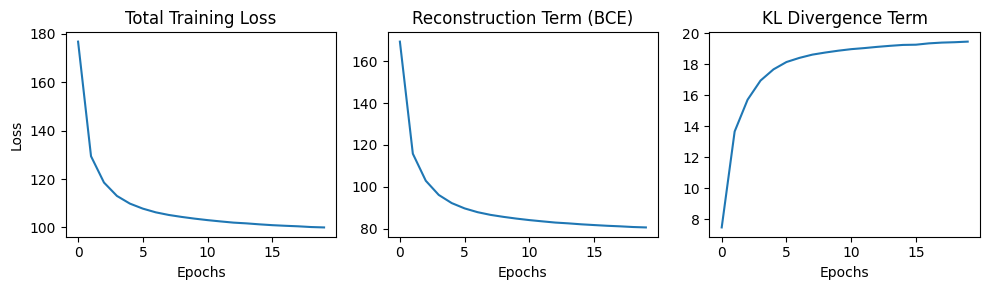

In [558]:
# Train models
model = train_vae(model=VAE(), epochs=20)

In [559]:
summary(model, input_size=(1, 28, 28))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                  [-1, 512]         401,920
            Linear-2                  [-1, 256]         131,328
            Linear-3                   [-1, 20]           5,140
            Linear-4                   [-1, 20]           5,140
            Linear-5                  [-1, 256]           5,376
            Linear-6                  [-1, 512]         131,584
            Linear-7                  [-1, 784]         402,192
Total params: 1,082,680
Trainable params: 1,082,680
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.02
Params size (MB): 4.13
Estimated Total Size (MB): 4.15
----------------------------------------------------------------


## Task 2 [20% marks] Reconstruction vs generation.

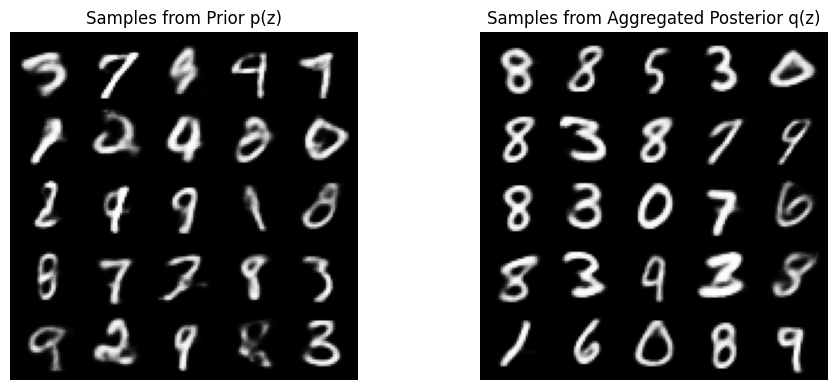

In [560]:
# Generate from prior p(z)
model = model.to(device)
model.eval()
num_samples = 25
z_prior = torch.randn(num_samples, 20).to(device)
with torch.no_grad():
    generated_from_prior = model.decode(z_prior)

# Generate from Aggregated Posterior q(z)
data_iter = iter(test_loader) # Get a batch of real data
real_images, _ = next(data_iter)
real_images = real_images[:num_samples]
real_images = real_images.to(device)
with torch.no_grad():
    # Encode real data
    mu, logvar = model.encode(real_images.view(-1, 784))
    # Sample z from the encoder's output
    z_posterior = model.reparameterize(mu, logvar)
    # Decode
    generated_from_posterior = model.decode(z_posterior)

# Helper to create a grid of images
def plot_grid(tensor, title, ax):
    # Reshape to (Batch, Channel, Height, Width)
    tensor = tensor.cpu().view(-1, 1, 28, 28)
    grid = vutils.make_grid(tensor, nrow=5, padding=2, normalize=False)
    ax.imshow(grid.permute(1, 2, 0), cmap='gray')
    ax.axis('off')
    ax.set_title(title)

# Plot prior and posterior samples
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_grid(generated_from_prior, "Samples from Prior p(z)", axes[0])
plot_grid(generated_from_posterior, "Samples from Aggregated Posterior q(z)", axes[1])
plt.tight_layout()
plt.show()

## Task 3 [20% marks] Comparing the prior and the aggregated posterior.

In [584]:
from sklearn.decomposition import PCA
from scipy.stats import wasserstein_distance

# Define helper function to collect samples
def get_latent_samples(model, dataloader, num_samples=2000):

    torch.manual_seed(42)
    rng = np.random.default_rng(42)
    model.eval()
    z_posterior_list = []
    labels_list = []

    with torch.no_grad():
        for x, label in dataloader:
            x = x.to(device)
            # Encode to get q(z|x)
            mu, logvar = model.encode(x.view(-1, 784))
            # Sample z (Reparameterization)
            z = model.reparameterize(mu, logvar)

            z_posterior_list.append(z.cpu().numpy())
            labels_list.append(label.numpy())

            if len(np.concatenate(z_posterior_list)) >= num_samples:
                break

    z_posterior = np.concatenate(z_posterior_list)[:num_samples]
    labels = np.concatenate(labels_list)[:num_samples]
    z_prior = rng.normal(0, 1, size=z_posterior.shape)

    return z_posterior, z_prior, labels

z_posterior, z_prior, labels = get_latent_samples(model, test_loader, num_samples=2000)

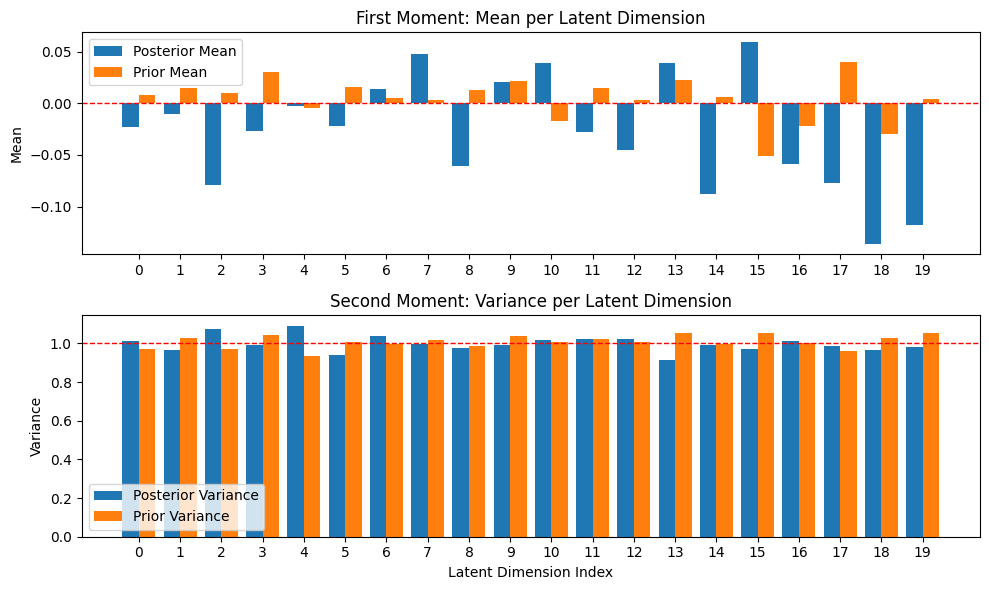

In [585]:
def compare_moments(z_posterior, z_prior):
    """
    Compares the Mean and Variance of the Posterior vs Prior per dimension.
    """
    latent_dim = z_posterior.shape[1]

    # Calculate posterior moments
    post_mean = np.mean(z_posterior, axis=0)
    post_var = np.var(z_posterior, axis=0)

    # Calculate prior moments
    prior_mean = np.mean(z_prior, axis=0)
    prior_var = np.var(z_prior, axis=0)

    # Plotting
    fig, axes = plt.subplots(2, 1, figsize=(10, 6))

    # Mean Comparison
    axes[0].bar(np.arange(latent_dim) - 0.2, post_mean, width=0.4, label='Posterior Mean')
    axes[0].bar(np.arange(latent_dim) + 0.2, prior_mean, width=0.4, label='Prior Mean')
    axes[0].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[0].set_ylabel("Mean")
    axes[0].set_title("First Moment: Mean per Latent Dimension")
    axes[0].set_xticks(np.arange(latent_dim))
    axes[0].legend()

    # Variance Comparison
    axes[1].bar(np.arange(latent_dim) - 0.2, post_var, width=0.4, label='Posterior Variance')
    axes[1].bar(np.arange(latent_dim) + 0.2, prior_var, width=0.4, label='Prior Variance')
    axes[1].axhline(1, color='red', linestyle='--', linewidth=1)
    axes[1].set_ylabel("Variance")
    axes[1].set_title("Second Moment: Variance per Latent Dimension")
    axes[1].set_xlabel("Latent Dimension Index")
    axes[1].set_xticks(np.arange(latent_dim))
    axes[1].legend()

    plt.tight_layout()
    plt.show()

compare_moments(z_posterior, z_prior)

Text(0, 0.5, 'Latent Dimension Index')

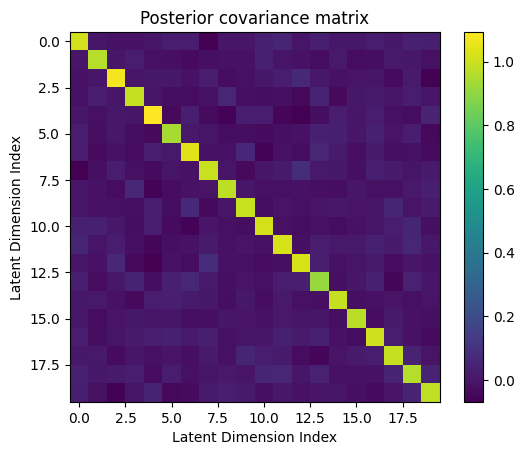

In [586]:
cov = np.cov(z_posterior, rowvar=False)

plt.imshow(cov)
plt.colorbar()
plt.title("Posterior covariance matrix")
plt.xlabel("Latent Dimension Index")
plt.ylabel("Latent Dimension Index")


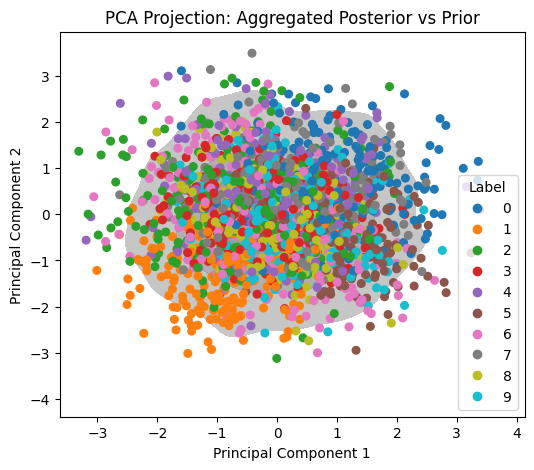

In [587]:
def analyse_pca(z_posterior, z_prior, labels, title=None):
    # Fit PCA on the posterior
    pca = PCA(n_components=2)
    z_post_2d = pca.fit_transform(z_posterior)

    # Project prior into the same subspace
    z_prior_2d = pca.transform(z_prior)

    plt.figure(figsize=(6, 5))

    # Plot prior as a background density
    # Using a KDE plot for the prior to show density regions clearly
    sns.kdeplot(x=z_prior_2d[:, 0], y=z_prior_2d[:, 1],
                levels=5, color='black', alpha=0.8, fill=True, label='Prior Density p(z)')

    # Plot posterior as scatter points colored by label
    scatter = plt.scatter(z_post_2d[:, 0], z_post_2d[:, 1],
                        c=labels, cmap='tab10', s=30)

    plt.legend(*scatter.legend_elements(), title="Label")
    plt.title(title)
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.show()

analyse_pca(z_posterior, z_prior, labels, "PCA Projection: Aggregated Posterior vs Prior")


Total Wasserstein Distance (Prior vs Posterior): 1.4476
Baseline Distance (Prior vs Prior)             : 0.7353
Ratio (Total to baseline): 1.97x


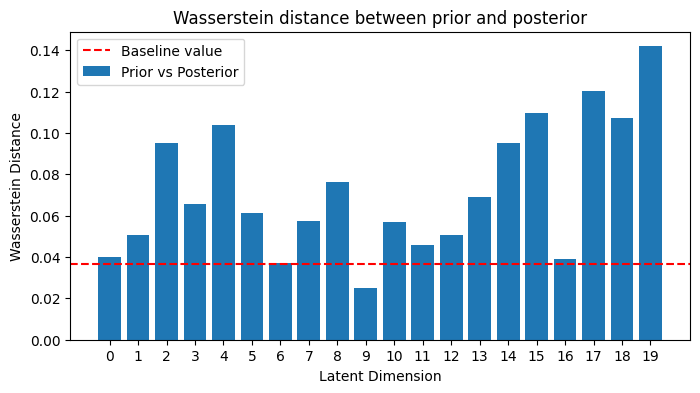

In [588]:
def evaluate_wasserstein(z_posterior, z_prior):
    rng = np.random.default_rng(42)
    latent_dim = z_posterior.shape[1]

    # Compute WD between prior and osterior
    wd = []
    for i in range(latent_dim):
        wd.append(wasserstein_distance(z_posterior[:, i], z_prior[:, i]))
    total_wd = np.sum(wd)

    # Compute Baseline (Control Group)
    # Distance between two random batches of N(0,1) to see what "0" looks like with sampling noise
    z_prior_batch_1 = rng.normal(0, 1, size=z_posterior.shape)
    z_prior_batch_2 = rng.normal(0, 1, size=z_posterior.shape)

    baseline_wd = []
    for i in range(latent_dim):
        baseline_wd.append(wasserstein_distance(z_prior_batch_1[:, i], z_prior_batch_2[:, i]))
    total_baseline_wd = np.sum(baseline_wd)

    print(f"Total Wasserstein Distance (Prior vs Posterior): {total_wd:.4f}")
    print(f"Baseline Distance (Prior vs Prior)             : {total_baseline_wd:.4f}")
    print(f"Ratio (Total to baseline): {total_wd / total_baseline_wd:.2f}x")

    # Optional: Plot WD per dimension to see which dimensions are "broken"
    plt.figure(figsize=(8, 4))
    plt.bar(range(latent_dim), wd, label='Prior vs Posterior')
    plt.axhline(np.mean(baseline_wd), color='red', linestyle='--', label='Baseline value')
    plt.xticks(np.arange(latent_dim))
    plt.xlabel("Latent Dimension")
    plt.ylabel("Wasserstein Distance")
    plt.title("Wasserstein distance between prior and posterior")
    plt.legend()
    plt.show()

evaluate_wasserstein(z_posterior, z_prior)

## Task 4 [20% marks] Reconstruction and regularisation.

In [517]:
def loss_function_beta(recon_x, x, mu, logvar, beta):
    # Reconstruction Loss (Binary Cross Entropy)
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 784), reduction='sum')
    # KL Divergence
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    # Total Loss with beta weighting
    total_loss = BCE + (beta * KLD)

    return total_loss, BCE, KLD


def train_vae_beta(model, beta, epochs=20):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Training on: {device}")
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    train_losses = []
    recon_losses = []
    kld_losses = []
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        recon_loss = 0
        kl_loss = 0
        for data, _ in train_loader:
            data = data.to(device)
            optimizer.zero_grad()
            recon_batch, mu, logvar = model(data)
            loss, bce, kld = loss_function_beta(recon_batch, data, mu, logvar, beta=beta)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            recon_loss += bce.item()
            kl_loss += kld.item()

        # Calculate averages for the epoch
        num_samples = len(train_loader.dataset)
        avg_loss = train_loss / num_samples
        avg_recon = recon_loss / num_samples
        avg_kld = kl_loss / num_samples
        train_losses.append(avg_loss)
        recon_losses.append(avg_recon)
        kld_losses.append(avg_kld)

        print(f'Epoch: {epoch+1} | Loss: {avg_loss:.4f} | Recon: {avg_recon:.4f} | KLD: {avg_kld:.4f}')

    # Plotting
    fig = plt.figure(figsize=(10, 3))
    fig.suptitle(f"Training loss for beta = {beta}")

    # Plot 1: Total Loss
    plt.subplot(1, 3, 1)
    plt.plot(train_losses)
    plt.title("Total Training Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")

    # Plot 2: Reconstruction Loss
    plt.subplot(1, 3, 2)
    plt.plot(recon_losses)
    plt.title("Reconstruction Term (BCE)")
    plt.xlabel("Epochs")

    # Plot 3: KL Divergence
    plt.subplot(1, 3, 3)
    plt.plot(kld_losses)
    plt.title("KL Divergence Term")
    plt.xlabel("Epochs")

    plt.tight_layout()
    plt.show()

    return model

Training on: cpu


Epoch: 1 | Loss: 157.3274 | Recon: 154.3200 | KLD: 30.0745
Epoch: 2 | Loss: 99.1019 | Recon: 94.1567 | KLD: 49.4522
Epoch: 3 | Loss: 87.0653 | Recon: 81.9220 | KLD: 51.4326
Epoch: 4 | Loss: 81.1230 | Recon: 75.8975 | KLD: 52.2556
Epoch: 5 | Loss: 77.6211 | Recon: 72.3599 | KLD: 52.6121
Epoch: 6 | Loss: 75.5605 | Recon: 70.2763 | KLD: 52.8423
Epoch: 7 | Loss: 74.2415 | Recon: 68.9547 | KLD: 52.8673
Epoch: 8 | Loss: 73.3116 | Recon: 68.0169 | KLD: 52.9464
Epoch: 9 | Loss: 72.6213 | Recon: 67.3228 | KLD: 52.9842
Epoch: 10 | Loss: 72.0216 | Recon: 66.7234 | KLD: 52.9820
Epoch: 11 | Loss: 71.4897 | Recon: 66.1876 | KLD: 53.0214
Epoch: 12 | Loss: 71.1153 | Recon: 65.8166 | KLD: 52.9872
Epoch: 13 | Loss: 70.7444 | Recon: 65.4464 | KLD: 52.9805
Epoch: 14 | Loss: 70.4454 | Recon: 65.1365 | KLD: 53.0882
Epoch: 15 | Loss: 70.1470 | Recon: 64.8365 | KLD: 53.1049
Epoch: 16 | Loss: 69.8789 | Recon: 64.5728 | KLD: 53.0611
Epoch: 17 | Loss: 69.6503 | Recon: 64.3442 | KLD: 53.0610
Epoch: 18 | Loss: 69.

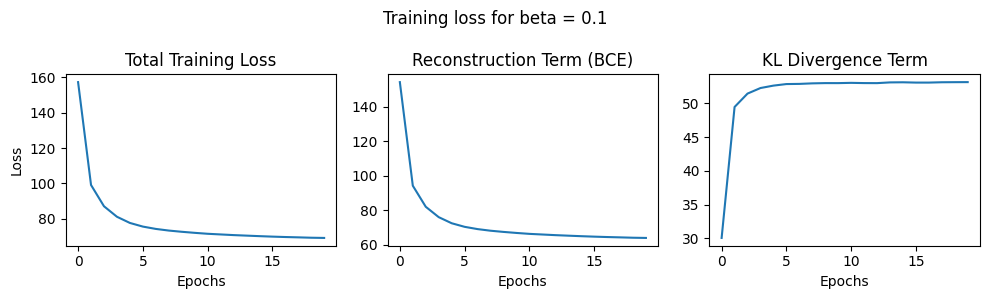

Training on: cpu
Epoch: 1 | Loss: 209.5317 | Recon: 205.3227 | KLD: 0.4209
Epoch: 2 | Loss: 198.1700 | Recon: 187.9551 | KLD: 1.0215
Epoch: 3 | Loss: 192.9314 | Recon: 174.4065 | KLD: 1.8525
Epoch: 4 | Loss: 188.6377 | Recon: 164.0219 | KLD: 2.4616
Epoch: 5 | Loss: 186.6098 | Recon: 159.2105 | KLD: 2.7399
Epoch: 6 | Loss: 185.4166 | Recon: 156.4475 | KLD: 2.8969
Epoch: 7 | Loss: 184.8306 | Recon: 154.4857 | KLD: 3.0345
Epoch: 8 | Loss: 183.9590 | Recon: 152.4897 | KLD: 3.1469
Epoch: 9 | Loss: 183.5715 | Recon: 151.1455 | KLD: 3.2426
Epoch: 10 | Loss: 183.1785 | Recon: 150.1511 | KLD: 3.3027
Epoch: 11 | Loss: 182.8997 | Recon: 149.3437 | KLD: 3.3556
Epoch: 12 | Loss: 182.6881 | Recon: 148.7442 | KLD: 3.3944
Epoch: 13 | Loss: 182.3691 | Recon: 148.0230 | KLD: 3.4346
Epoch: 14 | Loss: 182.1134 | Recon: 147.3636 | KLD: 3.4750
Epoch: 15 | Loss: 182.0207 | Recon: 146.8580 | KLD: 3.5163
Epoch: 16 | Loss: 181.9159 | Recon: 146.4022 | KLD: 3.5514
Epoch: 17 | Loss: 181.5733 | Recon: 146.0031 | K

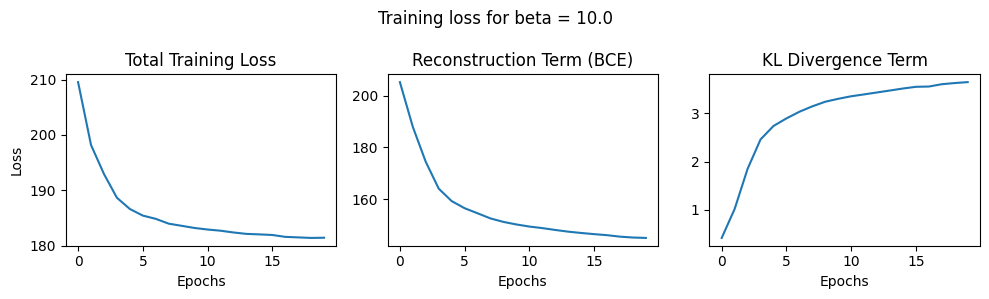

In [518]:
# Train models
model_low_beta = train_vae_beta(model=VAE().to(device), beta=0.1)
model_high_beta = train_vae_beta(model=VAE().to(device), beta=10.0)

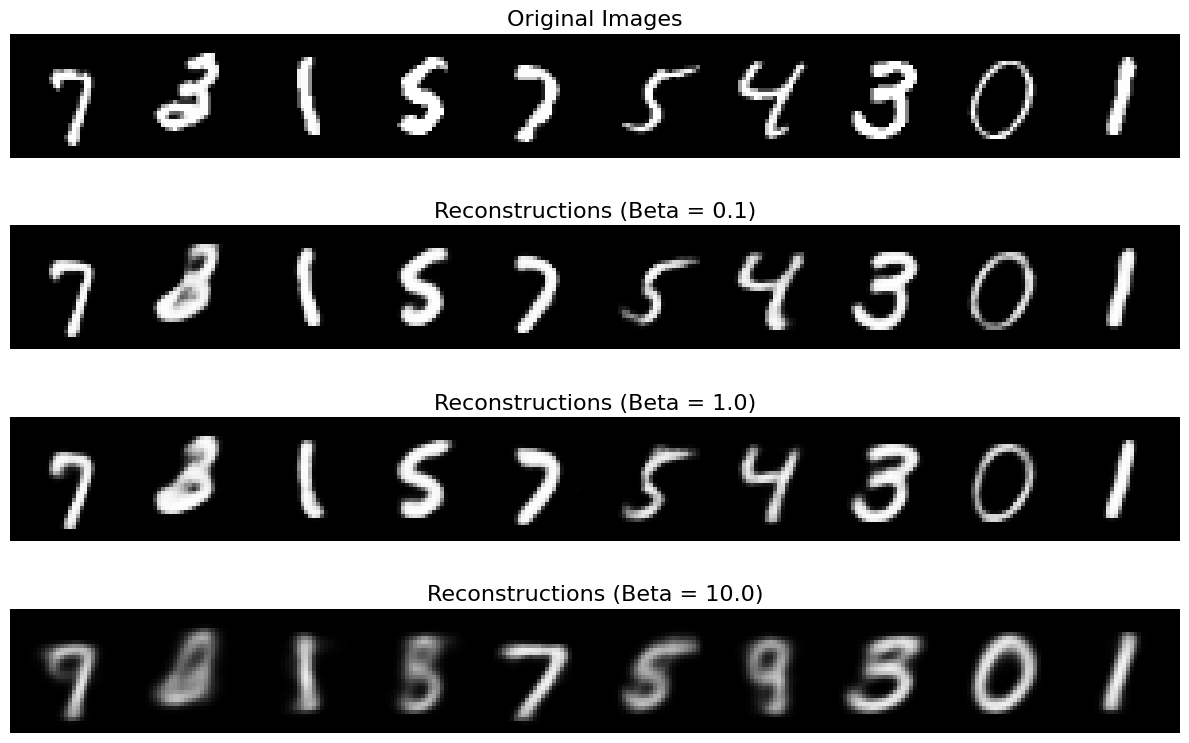

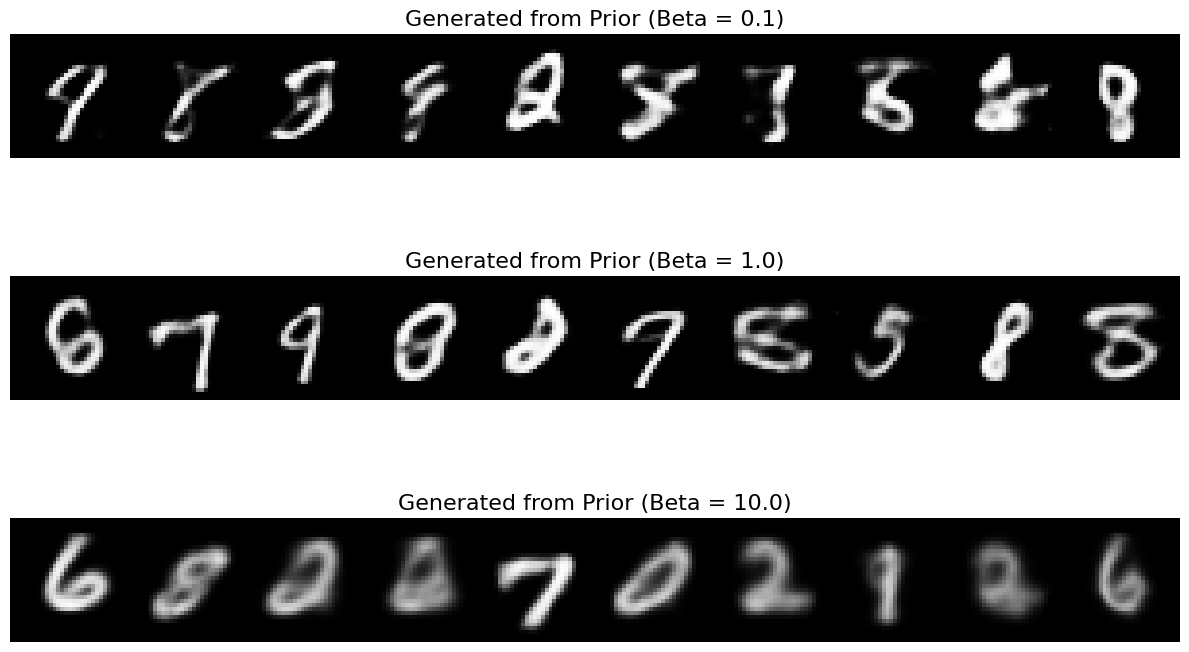

In [519]:
model.eval()
model_high_beta.eval()
model_low_beta.eval()

# Take just the first 10 images for reconstruction
num_samples = 10
data_iter = iter(test_loader)
real_images, _ = next(data_iter)
real_images = real_images[:num_samples].to(device)

# Generate 10 random latent vectors from the standard Normal prior
z_prior = torch.randn(num_samples, 20).to(device)

with torch.no_grad():
    # Reconstructions
    recon_baseline = model(real_images)[0]
    recon_low = model_low_beta(real_images)[0]
    recon_high = model_high_beta(real_images)[0]

    # Generations
    gen_baseline = model.decode(z_prior)
    gen_low = model_low_beta.decode(z_prior)
    gen_high = model_high_beta.decode(z_prior)

# Create image grids
grid_real     = vutils.make_grid(real_images.cpu().view(-1, 1, 28, 28), nrow=10, padding=2)
grid_recon_low      = vutils.make_grid(recon_low.cpu().view(-1, 1, 28, 28), nrow=10, padding=2)
grid_recon_baseline = vutils.make_grid(recon_baseline.cpu().view(-1, 1, 28, 28), nrow=10, padding=2)
grid_recon_high     = vutils.make_grid(recon_high.cpu().view(-1, 1, 28, 28), nrow=10, padding=2)
grid_gen_low      = vutils.make_grid(gen_low.cpu().view(-1, 1, 28, 28), nrow=10, padding=2)
grid_gen_baseline = vutils.make_grid(gen_baseline.cpu().view(-1, 1, 28, 28), nrow=10, padding=2)
grid_gen_high     = vutils.make_grid(gen_high.cpu().view(-1, 1, 28, 28), nrow=10, padding=2)

# Plot reconstructions
fig1, axes1 = plt.subplots(4, 1, figsize=(12, 8))

axes1[0].imshow(grid_real.permute(1, 2, 0), cmap='gray')
axes1[0].set_title("Original Images", fontsize=16)
axes1[0].axis('off')

axes1[1].imshow(grid_recon_low.permute(1, 2, 0), cmap='gray')
axes1[1].set_title("Reconstructions (Beta = 0.1)", fontsize=16)
axes1[1].axis('off')

axes1[2].imshow(grid_recon_baseline.permute(1, 2, 0), cmap='gray')
axes1[2].set_title("Reconstructions (Beta = 1.0)", fontsize=16)
axes1[2].axis('off')

axes1[3].imshow(grid_recon_high.permute(1, 2, 0), cmap='gray')
axes1[3].set_title("Reconstructions (Beta = 10.0)", fontsize=16)
axes1[3].axis('off')

plt.tight_layout()
plt.show()

# Plot generation from priod
fig2, axes2 = plt.subplots(3, 1, figsize=(12, 8))

axes2[0].imshow(grid_gen_low.permute(1, 2, 0), cmap='gray')
axes2[0].set_title("Generated from Prior (Beta = 0.1)", fontsize=16)
axes2[0].axis('off')

axes2[1].imshow(grid_gen_baseline.permute(1, 2, 0), cmap='gray')
axes2[1].set_title("Generated from Prior (Beta = 1.0)", fontsize=16)
axes2[1].axis('off')

axes2[2].imshow(grid_gen_high.permute(1, 2, 0), cmap='gray')
axes2[2].set_title("Generated from Prior (Beta = 10.0)", fontsize=16)
axes2[2].axis('off')

plt.tight_layout()
plt.show()

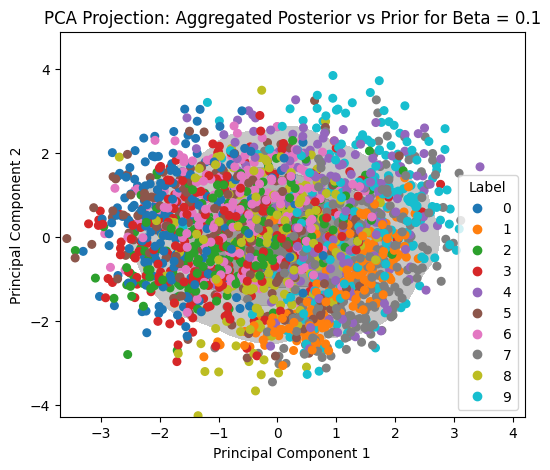

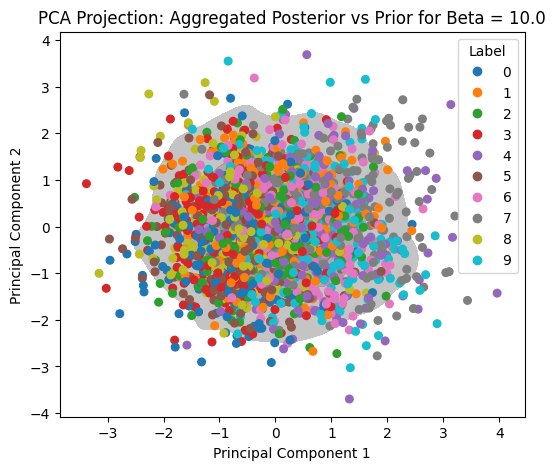

In [520]:
z_post_low, z_prior_low, labels_low = get_latent_samples(model_low_beta, train_loader)
analyse_pca(z_post_low, z_prior_low, labels_low, "PCA Projection: Aggregated Posterior vs Prior for Beta = 0.1")

z_post_high, z_prior_high, labels_high = get_latent_samples(model_high_beta, train_loader)
analyse_pca(z_post_high, z_prior_high, labels_high, "PCA Projection: Aggregated Posterior vs Prior for Beta = 10.0")

## Task 5 [15% marks] Improved architecture.

In [521]:
class CVAE(nn.Module):
    def __init__(self, latent_dim=20):
        super(CVAE, self).__init__()

        # --- Encoder --- 
        # Define convolutional layers
        # Input shape: (Batch=B, Channel=1, Height=28, Width=28)
        # Args: in_channels, out_channels, kernel_size, stride, padding
        self.conv1 = nn.Conv2d(1, 8, 3, 2, 1)  # (B, 8, 14, 14)
        self.conv2 = nn.Conv2d(8, 16, 3, 2, 1) # (B, 16, 7, 7)

        # Flattened size: 16 channels * 7 * 7 = 784
        self.flatten_dim = 16 * 7 * 7

        # Latent space parameters
        self.fc_mu = nn.Linear(self.flatten_dim, latent_dim) # (B, 20)
        self.fc_logvar = nn.Linear(self.flatten_dim, latent_dim) # (B, 20)

        # --- Decoder ---
        # Expand latent code (B, 20) back to flattened feature map (B, 784)
        self.fc_dec = nn.Linear(latent_dim, self.flatten_dim)

        # Transpose convolution layers
        # Input shape: (B,16,7,7)
        # Args: in_channels, out_channels, kernel_size, stride, padding, output_padding
        self.deconv1 = nn.ConvTranspose2d(16, 8, 3, 2, 1, 1) # (B, 8, 14, 14)
        self.deconv2 = nn.ConvTranspose2d(8, 1, 3, 2, 1, 1)  # (B, 1, 28, 28)

    def encode(self, x):
        # x: (B, 1, 28, 28)
        h = F.relu(self.conv1(x))               # (B, 8, 14 ,14)
        h = F.relu(self.conv2(h))               # (B, 16, 7, 7)
        h = h.view(-1, self.flatten_dim)        # (B, 784)
        return self.fc_mu(h), self.fc_logvar(h) # (B, 20)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        # z: (B, 20)
        h = self.fc_dec(z)          # (B, 784)
        h = h.view(-1, 16, 7, 7)    # (B, 16, 7, 7)
        h = F.relu(self.deconv1(h)) # (B, 8, 14, 14)
        return torch.sigmoid(self.deconv2(h)) # (B, 8, 14, 14)

    def forward(self, x):
        # Reshaped to image format (Batch, Channel, Height, Width)
        x = x.view(-1, 1, 28, 28)
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decode(z)

        return recon_x.view(-1, 784), mu, logvar

Training on: cpu


Epoch: 1 | Loss: 231.8641 | Recon: 210.2322 | KLD: 21.6319
Epoch: 2 | Loss: 131.9270 | Recon: 105.5782 | KLD: 26.3488
Epoch: 3 | Loss: 125.2644 | Recon: 98.2981 | KLD: 26.9663
Epoch: 4 | Loss: 122.1986 | Recon: 95.3000 | KLD: 26.8986
Epoch: 5 | Loss: 119.9364 | Recon: 93.1469 | KLD: 26.7895
Epoch: 6 | Loss: 117.9315 | Recon: 91.2301 | KLD: 26.7013
Epoch: 7 | Loss: 116.2017 | Recon: 89.6134 | KLD: 26.5883
Epoch: 8 | Loss: 114.8325 | Recon: 88.4068 | KLD: 26.4256
Epoch: 9 | Loss: 113.7108 | Recon: 87.3955 | KLD: 26.3153
Epoch: 10 | Loss: 112.7011 | Recon: 86.5048 | KLD: 26.1964
Epoch: 11 | Loss: 111.8884 | Recon: 85.7807 | KLD: 26.1077
Epoch: 12 | Loss: 111.1632 | Recon: 85.1218 | KLD: 26.0414
Epoch: 13 | Loss: 110.6437 | Recon: 84.6200 | KLD: 26.0237
Epoch: 14 | Loss: 110.1189 | Recon: 84.1604 | KLD: 25.9585
Epoch: 15 | Loss: 109.7681 | Recon: 83.8024 | KLD: 25.9657
Epoch: 16 | Loss: 109.4503 | Recon: 83.5079 | KLD: 25.9423
Epoch: 17 | Loss: 109.1384 | Recon: 83.2096 | KLD: 25.9288
Epoc

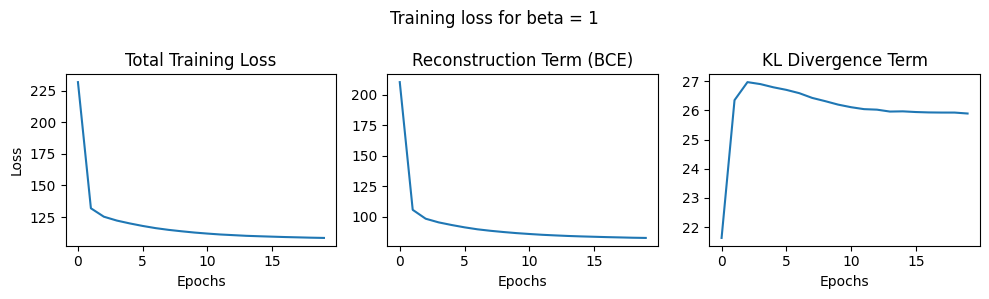

In [522]:
model_cnn = train_vae_beta(model=CVAE().to(device), beta=1)

In [576]:
summary(model_cnn, input_size=(1, 28, 28))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 8, 14, 14]              80
            Conv2d-2             [-1, 16, 7, 7]           1,168
            Linear-3                   [-1, 20]          15,700
            Linear-4                   [-1, 20]          15,700
            Linear-5                  [-1, 784]          16,464
   ConvTranspose2d-6            [-1, 8, 14, 14]           1,160
   ConvTranspose2d-7            [-1, 1, 28, 28]              73
Total params: 50,345
Trainable params: 50,345
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.04
Params size (MB): 0.19
Estimated Total Size (MB): 0.24
----------------------------------------------------------------


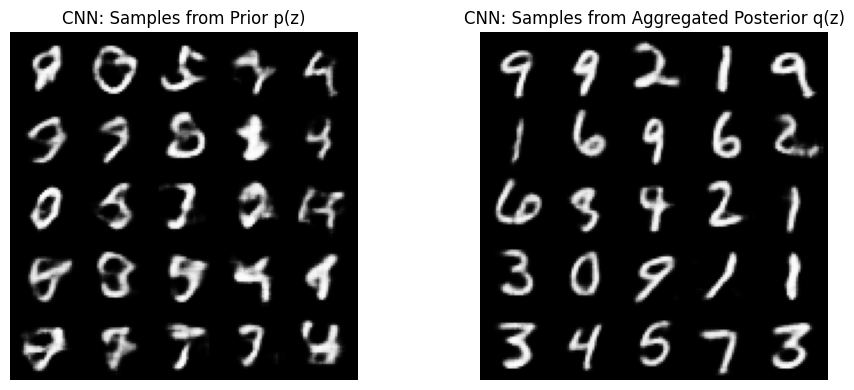

In [577]:
def compare_samples(model, dataloader, num_samples=25):
    model.eval()

    # Generate from Prior p(z)
    z_prior = torch.randn(num_samples, 20).to(device)
    with torch.no_grad():
        generated_from_prior = model.decode(z_prior).cpu()

    # Generate from Aggregated Posterior q(z)
    data_iter = iter(dataloader)
    real_images, _ = next(data_iter)
    real_images = real_images[:num_samples].to(device)

    with torch.no_grad():
        # Reshape for CNN: (-1, 1, 28, 28) instead of (-1, 784)
        enc_input = real_images.view(-1, 1, 28, 28)
        mu, logvar = model.encode(enc_input)
        z_posterior = model.reparameterize(mu, logvar)
        generated_from_posterior = model.decode(z_posterior).cpu()

    # Plotting
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    plot_grid(generated_from_prior, "CNN: Samples from Prior p(z)", axes[0])
    plot_grid(generated_from_posterior, "CNN: Samples from Aggregated Posterior q(z)", axes[1])
    plt.tight_layout()
    plt.show()

compare_samples(model_cnn, test_loader)

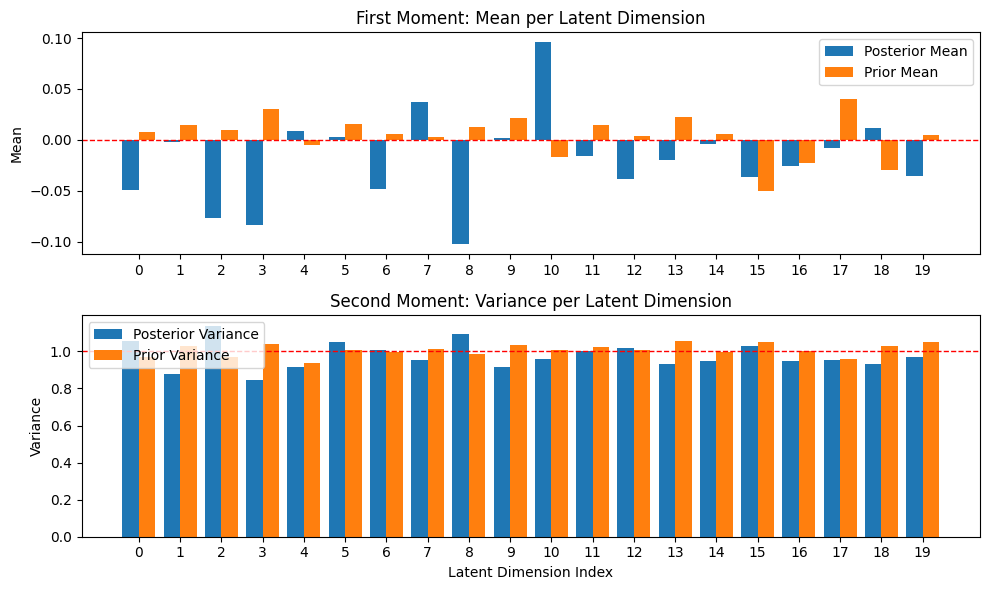

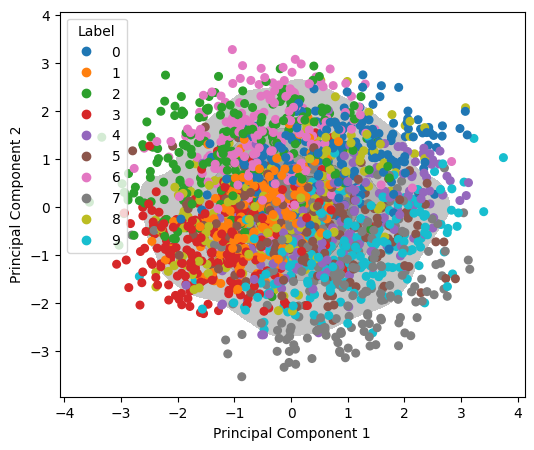

Total Wasserstein Distance (Prior vs Posterior): 1.3812
Baseline Distance (Prior vs Prior)             : 0.7353
Ratio (Total to baseline): 1.88x


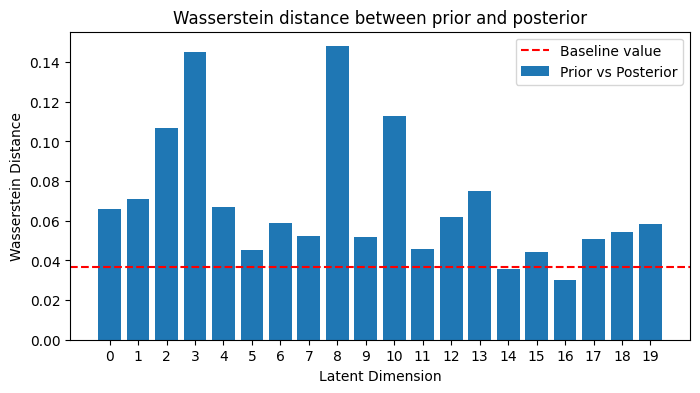

In [578]:
def get_latent_samples_cnn(model, dataloader, num_samples=2000):

    torch.manual_seed(42)
    rng = np.random.default_rng(42)
    model.eval()
    z_posterior_list = []
    labels_list = []

    with torch.no_grad():
        for x, label in dataloader:
            x = x.to(device)
            # Reshape for CNN
            x = x.view(-1, 1, 28, 28)
            # Encode to get q(z|x)
            mu, logvar = model.encode(x)
            # Sample z (Reparameterization)
            z = model.reparameterize(mu, logvar)

            z_posterior_list.append(z.cpu().numpy())
            labels_list.append(label.numpy())

            if len(np.concatenate(z_posterior_list)) >= num_samples:
                break

    z_posterior = np.concatenate(z_posterior_list)[:num_samples]
    labels = np.concatenate(labels_list)[:num_samples]
    z_prior = rng.normal(0, 1, size=z_posterior.shape)

    return z_posterior, z_prior, labels

z_post_cnn, z_prior_cnn, labels_cnn = get_latent_samples_cnn(model_cnn, test_loader, num_samples=2000)
compare_moments(z_post_cnn, z_prior_cnn)
analyse_pca(z_post_cnn, z_prior_cnn, labels_cnn)
evaluate_wasserstein(z_post_cnn, z_prior_cnn)